In [1]:
import pandas as pd

In [3]:
meta = pd.read_csv('~/comparison/metadata.txt', sep='\t')

In [4]:
meta

,project,fastq.1,fastq.2,experiment,dilution,amount_ng,chain,replica,umi
0,Adaptive,/RepSeq/RS_Data/Adaptive/Adapt003/fastQ/PBA056...,NaN,B,1000.0,100,TRB,1,False
1,Adaptive,/RepSeq/RS_Data/Adaptive/Adapt003/fastQ/PBA056...,NaN,B,1000.0,100,TRB,2,False
2,Adaptive,/RepSeq/RS_Data/Adaptive/Adapt003/fastQ/PBA056...,NaN,B,1000.0,100,TRB,3,False
3,Adaptive,/RepSeq/RS_Data/Adaptive/Adapt003/fastQ/PBA057...,NaN,B,100.0,100,TRB,1,False
4,Adaptive,/RepSeq/RS_Data/Adaptive/Adapt003/fastQ/PBA057...,NaN,B,100.0,100,TRB,2,False
...,...,...,...,...,...,...,...,...,...
229,Chudakov-2U,Chu_new/asm/100-2-beta_R1.t3.cf.fastq,Chu_new/asm/100-2-beta_R2.t3.cf.fastq,B,100.0,100,TRB,2,True
230,Chudakov-2U,Chu_new/asm/10-1-alpha_R1.t3.cf.fastq,Chu_new/asm/10-1-alpha_R2.t3.cf.fastq,B,10.0,100,TRA,1,True
231,Chudakov-2U,Chu_new/asm/10-1-beta_R1.t3.cf.fastq,Chu_new/asm/10-1-beta_R2.t3.cf.fastq,B,10.0,100,TRB,1,True
232,Chudakov-2U,Chu_new/asm/10-2-alpha_R1.t3.cf.fastq,Chu_new/asm/10-2-alpha_R2.t3.cf.fastq,B,10.0,100,TRA,2,True


In [5]:
meta.chain.value_counts()

chain
TRB    135
TRA     99
Name: count, dtype: int64

In [6]:
meta_beta = meta[meta.chain == 'TRB']

In [7]:
meta_beta

,project,fastq.1,fastq.2,experiment,dilution,amount_ng,chain,replica,umi
0,Adaptive,/RepSeq/RS_Data/Adaptive/Adapt003/fastQ/PBA056...,NaN,B,1000.0,100,TRB,1,False
1,Adaptive,/RepSeq/RS_Data/Adaptive/Adapt003/fastQ/PBA056...,NaN,B,1000.0,100,TRB,2,False
2,Adaptive,/RepSeq/RS_Data/Adaptive/Adapt003/fastQ/PBA056...,NaN,B,1000.0,100,TRB,3,False
3,Adaptive,/RepSeq/RS_Data/Adaptive/Adapt003/fastQ/PBA057...,NaN,B,100.0,100,TRB,1,False
4,Adaptive,/RepSeq/RS_Data/Adaptive/Adapt003/fastQ/PBA057...,NaN,B,100.0,100,TRB,2,False
...,...,...,...,...,...,...,...,...,...
225,Chudakov-2U,Chu_new/asm/1000-2-beta_R1.t3.cf.fastq,Chu_new/asm/1000-2-beta_R2.t3.cf.fastq,B,1000.0,100,TRB,2,True
227,Chudakov-2U,Chu_new/asm/100-1-beta_R1.t3.cf.fastq,Chu_new/asm/100-1-beta_R2.t3.cf.fastq,B,100.0,100,TRB,1,True
229,Chudakov-2U,Chu_new/asm/100-2-beta_R1.t3.cf.fastq,Chu_new/asm/100-2-beta_R2.t3.cf.fastq,B,100.0,100,TRB,2,True
231,Chudakov-2U,Chu_new/asm/10-1-beta_R1.t3.cf.fastq,Chu_new/asm/10-1-beta_R2.t3.cf.fastq,B,10.0,100,TRB,1,True


In [18]:
meta_beta.experiment.value_counts()

experiment
B    93
A    42
Name: count, dtype: int64

In [8]:
meta_beta.project.value_counts()

project
Chain-U        15
Chain          15
Chudakov       15
iRepertoire    15
Chudakov-U     15
Clontech       15
Invitrogen     15
Adaptive        9
Douek           9
Chudakov-2      6
Chudakov-2U     6
Name: count, dtype: int64

In [17]:
meta_beta.project.value_counts().sum()

135

In [11]:
import os
import re

path = "/home/evlasova/comparison/corrected"   # Путь к папке

files = os.listdir(path)

trb_files = [f for f in files if "TRB" in f]

prefixes = set()

for f in trb_files:
    # Берём часть до третьего элемента (например Adaptive_B_TRB)
    # Разбиваем по "_", ищем блок содержащий TRB и объединяем часть до него включительно
    parts = f.split("_")
    if "TRB" in parts:
        idx = parts.index("TRB")
        prefix = "_".join(parts[:idx+1])
        prefixes.add(prefix)

print("TRB файлы:")
for f in sorted(trb_files):
    print(f)

print("\nПрефиксы проектов:")
for p in sorted(prefixes):
    print(p)


TRB файлы:
Adaptive_B_TRB_1000_100_1.txt.gz
Adaptive_B_TRB_1000_100_2.txt.gz
Adaptive_B_TRB_1000_100_3.txt.gz
Adaptive_B_TRB_100_100_1.txt.gz
Adaptive_B_TRB_100_100_2.txt.gz
Adaptive_B_TRB_100_100_3.txt.gz
Adaptive_B_TRB_10_100_1.txt.gz
Adaptive_B_TRB_10_100_2.txt.gz
Adaptive_B_TRB_10_100_3.txt.gz
Chain-U_A_TRB_NA_100_1.txt.gz
Chain-U_A_TRB_NA_100_2.txt.gz
Chain-U_A_TRB_NA_100_3.txt.gz
Chain-U_A_TRB_NA_10_1.txt.gz
Chain-U_A_TRB_NA_10_2.txt.gz
Chain-U_A_TRB_NA_10_3.txt.gz
Chain-U_B_TRB_1000_100_1.txt.gz
Chain-U_B_TRB_1000_100_2.txt.gz
Chain-U_B_TRB_1000_100_3.txt.gz
Chain-U_B_TRB_100_100_1.txt.gz
Chain-U_B_TRB_100_100_2.txt.gz
Chain-U_B_TRB_100_100_3.txt.gz
Chain-U_B_TRB_10_100_1.txt.gz
Chain-U_B_TRB_10_100_2.txt.gz
Chain-U_B_TRB_10_100_3.txt.gz
Chain_A_TRB_NA_100_1.txt.gz
Chain_A_TRB_NA_100_2.txt.gz
Chain_A_TRB_NA_100_3.txt.gz
Chain_A_TRB_NA_10_1.txt.gz
Chain_A_TRB_NA_10_2.txt.gz
Chain_A_TRB_NA_10_3.txt.gz
Chain_B_TRB_1000_100_1.txt.gz
Chain_B_TRB_1000_100_2.txt.gz
Chain_B_TRB_1000_100

In [14]:
sorted(prefixes)

['Adaptive_B_TRB',
 'Chain-U_A_TRB',
 'Chain-U_B_TRB',
 'Chain_A_TRB',
 'Chain_B_TRB',
 'Chudakov-U_A_TRB',
 'Chudakov-U_B_TRB',
 'Chudakov_A_TRB',
 'Chudakov_B_TRB',
 'Clontech_A_TRB',
 'Clontech_B_TRB',
 'Douek_B_TRB',
 'Invitrogen_A_TRB',
 'Invitrogen_B_TRB',
 'Kashofer_B_TRB',
 'iRepertoire_A_TRB',
 'iRepertoire_B_TRB']

In [13]:
meta_beta.project.value_counts()

project
Chain-U        15
Chain          15
Chudakov       15
iRepertoire    15
Chudakov-U     15
Clontech       15
Invitrogen     15
Adaptive        9
Douek           9
Chudakov-2      6
Chudakov-2U     6
Name: count, dtype: int64

In [16]:
len(trb_files)

132

In [27]:
test = pd.read_csv('/home/evlasova/comparison/corrected/iRepertoire_A_TRB_NA_10_3.txt.gz', sep='\t')
test

,cloneId,cloneCount,cloneFraction,clonalSequence,clonalSequenceQuality,allVHitsWithScore,allDHitsWithScore,allJHitsWithScore,allCHitsWithScore,allVAlignments,...,nSeqFR4,minQualFR4,aaSeqFR1,aaSeqCDR1,aaSeqFR2,aaSeqCDR2,aaSeqFR3,aaSeqCDR3,aaSeqFR4,refPoints
0,0,13281,0.021474,TGTGCCAGCAGCCGCGGACTCTTCACAGATACGCAGTATTTT,GGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGG,TRBV11-2*00(1062.1),TRBD2*00(25),TRBJ2-3*00(234.2),TRBC2*00(258.1),330|342|367|0|12||60.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CASSRGLFTDTQYF,NaN,:::::::::0:-5:12:15:-1:-10:20:23:-2:42:::
1,1,11162,0.018048,TGCAGTGCTAGTCGACAGGGGAGGAATCAGCCCCAGCATTTT,GGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGG,TRBV20-1*00(1163.9),TRBD1*00(40),TRBJ1-5*00(229.3),TRBC1*00(258.1),321|332|355|0|11||55.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CSASRQGRNQPQHF,NaN,:::::::::0:-3:11:13:-2:-2:21:24:-4:42:::
2,2,5366,0.008676,TGTGCCTGGAGTTCTTCCGGGACTAGGCCAGATACGCAGTATTTT,GGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGG,TRBV30*00(1130.2),TRBD2*00(50),TRBJ2-3*00(224.2),TRBC2*00(257.6),321|333|355|0|12||60.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CAWSSSGTRPDTQYF,NaN,:::::::::0:-2:12:16:2:-8:26:28:-4:45:::
3,3,5362,0.008670,TGCGCCAGCTCCCTAGCGGGAGCTTACGAGCAGTACTTC,GGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGG,TRBV10-2*00(1117.4),TRBD2*00(50),TRBJ2-7*00(213.6),TRBC2*00(257.9),327|336|364|0|9||45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CASSLAGAYEQYF,NaN,:::::::::0:-8:9:12:-4:-2:22:24:-4:39:::
4,4,4821,0.007795,TGTGCCTGGTCGGGAGGGTATACCGGGGAGCTGTTTTTT,GGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGG,TRBV30*00(1113.5),TRBD2*00(40),TRBJ2-2*00(229.7),TRBC2*00(258.2),321|330|355|0|9||45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CAWSGGYTGELFF,NaN,:::::::::0:-5:9:10:-8:0:18:21:-5:39:::
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6015,6015,1,0.000002,TGTGCCAGGATTAAGAGCAGTACTTC,GGGGGGGGGGGGGGGGGGGGFGGGFG,TRBV27*00(1115),NaN,TRBJ2-7*00(200),"TRBC2*00(260),TRBC1*00(228)",327|335|364|0|8||40.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CARI_EQYF,NaN,:::::::::0:-9:8:::::14:-7:26:::
6016,6016,1,0.000002,TGTGCCAGCCTACCCGGT,GGGGGGFGFGFFDCB?GG,TRBV27*00(1120),"TRBD1*00(25),TRBD2*00(25)",TRBJ2-3*00(145),"TRBC2*00(260),TRBC1*00(228)",327|336|364|0|9||45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CASLPG,NaN,:::::::::0:-8:9:12:3:-10:17:17:-20:18:::
6017,6017,1,0.000002,TGTGCCAGCCGACCCAGT,GGGGGGGGGGGGGGGGGG,TRBV27*00(1104),NaN,TRBJ2-3*00(145),TRBC2*00(208),327|336|364|0|9||45.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CASRPS,NaN,:::::::::0:-8:9:::::17:-20:18:::
6018,6018,1,0.000002,TGTGCCAACCGACCCGGT,FGFGGFFDF@7CEGGGGG,TRBV27*00(1110),"TRBD1*00(25),TRBD2*00(25)",TRBJ2-3*00(145),TRBC2*00(244),327|334|364|0|7||35.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CANRPG,NaN,:::::::::0:-10:7:12:3:-10:17:17:-20:18:::


In [29]:
test.columns

Index(['cloneId', 'cloneCount', 'cloneFraction', 'clonalSequence',
       'clonalSequenceQuality', 'allVHitsWithScore', 'allDHitsWithScore',
       'allJHitsWithScore', 'allCHitsWithScore', 'allVAlignments',
       'allDAlignments', 'allJAlignments', 'allCAlignments', 'nSeqFR1',
       'minQualFR1', 'nSeqCDR1', 'minQualCDR1', 'nSeqFR2', 'minQualFR2',
       'nSeqCDR2', 'minQualCDR2', 'nSeqFR3', 'minQualFR3', 'nSeqCDR3',
       'minQualCDR3', 'nSeqFR4', 'minQualFR4', 'aaSeqFR1', 'aaSeqCDR1',
       'aaSeqFR2', 'aaSeqCDR2', 'aaSeqFR3', 'aaSeqCDR3', 'aaSeqFR4',
       'refPoints'],
      dtype='object')

In [39]:
import pandas as pd
import re

def parse_gene(hit):
    """Взять первый ген из записи типа 'TRBV12-3*01(123)'"""
    if pd.isna(hit):
        return '.'
    return re.split(r'[*,(]', hit)[0]  # TRBV12-3*01 → TRBV12-3

def parse_refpoints(ref):
    """Разобрать refPoints: это строка вида '0:45:67:89:100:120:150'"""
    pts = list(map(int, ref.split(':')))
    # индексы соответствуют VEnd,DStart,DEnd,JStart
    return {
        "VEnd": pts[3],
        "DStart": pts[4] if len(pts) > 4 else None,
        "DEnd": pts[5] if len(pts) > 5 else None,
        "JStart": pts[6] if len(pts) > 6 else None,
    }

def convert_mixcr(df):
    out = pd.DataFrame()

    out["count"] = df["cloneCount"]
    out["freq"] = df["cloneFraction"]
    out["cdr3nt"] = df["clonalSequence"]
    out["cdr3aa"] = df["aaSeqCDR3"]

    out["v"] = df["allVHitsWithScore"].apply(parse_gene)
    out["d"] = df["allDHitsWithScore"].apply(parse_gene)
    out["j"] = df["allJHitsWithScore"].apply(parse_gene)

    # # парсим refPoints
    # ref_parsed = df["refPoints"].apply(parse_refpoints)
    # out["VEnd"] = ref_parsed.apply(lambda x: x["VEnd"])
    # out["DStart"] = ref_parsed.apply(lambda x: x["DStart"])
    # out["DEnd"] = ref_parsed.apply(lambda x: x["DEnd"])
    # out["JStart"] = ref_parsed.apply(lambda x: x["JStart"])

    return out

result = convert_mixcr(test)
result

,count,freq,cdr3nt,cdr3aa,v,d,j
0,13281,0.021474,TGTGCCAGCAGCCGCGGACTCTTCACAGATACGCAGTATTTT,CASSRGLFTDTQYF,TRBV11-2,TRBD2,TRBJ2-3
1,11162,0.018048,TGCAGTGCTAGTCGACAGGGGAGGAATCAGCCCCAGCATTTT,CSASRQGRNQPQHF,TRBV20-1,TRBD1,TRBJ1-5
2,5366,0.008676,TGTGCCTGGAGTTCTTCCGGGACTAGGCCAGATACGCAGTATTTT,CAWSSSGTRPDTQYF,TRBV30,TRBD2,TRBJ2-3
3,5362,0.008670,TGCGCCAGCTCCCTAGCGGGAGCTTACGAGCAGTACTTC,CASSLAGAYEQYF,TRBV10-2,TRBD2,TRBJ2-7
4,4821,0.007795,TGTGCCTGGTCGGGAGGGTATACCGGGGAGCTGTTTTTT,CAWSGGYTGELFF,TRBV30,TRBD2,TRBJ2-2
...,...,...,...,...,...,...,...
6015,1,0.000002,TGTGCCAGGATTAAGAGCAGTACTTC,CARI_EQYF,TRBV27,.,TRBJ2-7
6016,1,0.000002,TGTGCCAGCCTACCCGGT,CASLPG,TRBV27,TRBD1,TRBJ2-3
6017,1,0.000002,TGTGCCAGCCGACCCAGT,CASRPS,TRBV27,.,TRBJ2-3
6018,1,0.000002,TGTGCCAACCGACCCGGT,CANRPG,TRBV27,TRBD1,TRBJ2-3


In [40]:
import os
import re
import pandas as pd

src_dir = "/home/evlasova/comparison/corrected"
dst_dir = "/home/evlasova/comparison/vdjtools_format"
os.makedirs(dst_dir, exist_ok=True)

# обработка всех TRB файлов
for fname in os.listdir(src_dir):
    if "TRB" not in fname:
        continue

    fpath = os.path.join(src_dir, fname)
    print("Processing:", fname)

    try:
        df = pd.read_csv(fpath, sep="\t")
    except:
        df = pd.read_csv(fpath, sep="\t", compression="gzip")

    out = convert_mixcr(df)

    out_name = fname.replace(".txt.gz", ".txt").replace(".gz", ".txt")
    out_path = os.path.join(dst_dir, out_name)

    out.to_csv(out_path, sep="\t", index=False)

print("Готово!")


Processing: Chudakov_A_TRB_NA_10_3.txt.gz
Processing: Invitrogen_A_TRB_NA_100_2.txt.gz
Processing: Chain-U_B_TRB_10_100_1.txt.gz
Processing: Invitrogen_B_TRB_100_100_3.txt.gz
Processing: Chain_B_TRB_100_100_3.txt.gz
Processing: Chudakov_A_TRB_NA_10_2.txt.gz
Processing: Chudakov_B_TRB_10_100_4.txt.gz
Processing: Chain-U_A_TRB_NA_100_3.txt.gz
Processing: Chudakov-U_A_TRB_NA_100_2.txt.gz


/scratch/ipykernel_2660811/1127682817.py:18: DtypeWarning: Columns (8,12) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(fpath, sep="\t")


Processing: Douek_B_TRB_10_100_1.txt.gz


/scratch/ipykernel_2660811/1127682817.py:18: DtypeWarning: Columns (12) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(fpath, sep="\t")


Processing: Adaptive_B_TRB_100_100_1.txt.gz
Processing: Clontech_B_TRB_100_100_3.txt.gz
Processing: Chain-U_B_TRB_100_100_3.txt.gz
Processing: Chain_B_TRB_1000_100_2.txt.gz
Processing: Chain-U_B_TRB_1000_100_1.txt.gz
Processing: Chudakov_B_TRB_100_100_3.txt.gz
Processing: Kashofer_B_TRB_1000_100_1.txt.gz
Processing: Adaptive_B_TRB_100_100_3.txt.gz
Processing: Invitrogen_A_TRB_NA_100_3.txt.gz
Processing: Invitrogen_B_TRB_10_100_2.txt.gz
Processing: Clontech_A_TRB_NA_10_3.txt.gz
Processing: Chain_A_TRB_NA_100_3.txt.gz


/scratch/ipykernel_2660811/1127682817.py:18: DtypeWarning: Columns (12) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(fpath, sep="\t")


... (11 outputs left out)

/scratch/ipykernel_2660811/1127682817.py:18: DtypeWarning: Columns (12) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(fpath, sep="\t")


Processing: iRepertoire_B_TRB_100_100_3.txt.gz
Processing: Chudakov_B_TRB_100_100_4.txt.gz
Processing: Chain_B_TRB_10_100_3.txt.gz
Processing: Adaptive_B_TRB_10_100_3.txt.gz
Processing: Kashofer_B_TRB_1000_100_3.txt.gz
Processing: Adaptive_B_TRB_10_100_1.txt.gz
Processing: Chain-U_B_TRB_10_100_2.txt.gz
Processing: iRepertoire_B_TRB_10_100_3.txt.gz
Processing: Chudakov-U_B_TRB_10_100_4.txt.gz
Processing: Chudakov_B_TRB_100_100_2.txt.gz
Processing: iRepertoire_A_TRB_NA_100_1.txt.gz
Processing: Clontech_B_TRB_100_100_2.txt.gz
Processing: Chudakov-U_B_TRB_1000_100_4.txt.gz
Processing: Chudakov-U_B_TRB_1000_100_3.txt.gz
Processing: Chudakov_A_TRB_NA_100_3.txt.gz
Processing: Chain-U_A_TRB_NA_10_3.txt.gz
Processing: Chudakov-U_A_TRB_NA_100_3.txt.gz
Processing: iRepertoire_B_TRB_1000_100_2.txt.gz
Processing: Chain_A_TRB_NA_10_1.txt.gz
Processing: Chain_A_TRB_NA_10_3.txt.gz
Processing: Invitrogen_B_TRB_10_100_1.txt.gz
Processing: Chain_A_TRB_NA_10_2.txt.gz
Processing: iRepertoire_B_TRB_1000_100

/scratch/ipykernel_2660811/1127682817.py:18: DtypeWarning: Columns (12) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(fpath, sep="\t")


Processing: Chain-U_B_TRB_1000_100_2.txt.gz
Processing: Chudakov-U_B_TRB_10_100_1.txt.gz
Processing: Kashofer_B_TRB_100_100_1.txt.gz
Processing: iRepertoire_A_TRB_NA_10_2.txt.gz
Processing: Douek_B_TRB_100_100_3.txt.gz
Готово!


In [41]:
import os
import re
import pandas as pd

path = "/home/evlasova/comparison/vdjtools_format"

files = os.listdir(path)
trb_files = [f for f in files if "TRB" in f]

project_names = []
for f in trb_files:
    # ищем шаблон "*_A_TRB" или "*_B_TRB"
    m = re.match(r"(.+?)_[AB]_TRB", f)
    if m:
        project = m.group(1)
    else:
        project = None  # если что-то странное
    project_names.append(project)

df = pd.DataFrame({
    "filename": trb_files,
    "project": project_names
})

print(df)


                           filename      project
0         Chain_B_TRB_100_100_1.txt        Chain
1     Adaptive_B_TRB_1000_100_3.txt     Adaptive
2       Clontech_B_TRB_10_100_2.txt     Clontech
3    Invitrogen_B_TRB_100_100_3.txt   Invitrogen
4     iRepertoire_A_TRB_NA_10_3.txt  iRepertoire
..                              ...          ...
127  iRepertoire_A_TRB_NA_100_2.txt  iRepertoire
128     Kashofer_B_TRB_10_100_3.txt     Kashofer
129    Clontech_B_TRB_100_100_2.txt     Clontech
130     Chudakov_B_TRB_10_100_1.txt     Chudakov
131      Chain-U_B_TRB_10_100_2.txt      Chain-U

[132 rows x 2 columns]


In [42]:
df

,filename,project
0,Chain_B_TRB_100_100_1.txt,Chain
1,Adaptive_B_TRB_1000_100_3.txt,Adaptive
2,Clontech_B_TRB_10_100_2.txt,Clontech
3,Invitrogen_B_TRB_100_100_3.txt,Invitrogen
4,iRepertoire_A_TRB_NA_10_3.txt,iRepertoire
...,...,...
127,iRepertoire_A_TRB_NA_100_2.txt,iRepertoire
128,Kashofer_B_TRB_10_100_3.txt,Kashofer
129,Clontech_B_TRB_100_100_2.txt,Clontech
130,Chudakov_B_TRB_10_100_1.txt,Chudakov


In [43]:
df.project.value_counts()

project
Chain          15
Clontech       15
Chain-U        15
Invitrogen     15
iRepertoire    15
Chudakov       15
Chudakov-U     15
Adaptive        9
Kashofer        9
Douek           9
Name: count, dtype: int64

In [44]:
from mir.common.parser import *
from mir.common.repertoire import Repertoire
from mir.common.repertoire_dataset import RepertoireDataset
from mir.basic.segment_usage import *
from mir.basic.sampling import RepertoireSampling
import time

In [45]:
t0 = time.time()
dataset = RepertoireDataset.load(parser=VDJtoolsParser(sep='\t'), 
                                 metadata=df,
                                 threads=28,
                                 paths=['/home/evlasova/comparison/vdjtools_format/' + r['filename']
                                        for _, r in df.iterrows()])
print(time.time() - t0)

loading Repertoire objects: 100%|██████████| 132/132 [00:20<00:00,  6.39it/s]


21.145443439483643


In [46]:
dataset.evaluate_segment_usage()

,TRBV11-1*01,TRBV6-9*01,TRBV7-3*01,TRBV13*01,TRBV22-1*01,TRBJ2-6*01,TRBV7-8*01,TRBV7-9*01,TRBJ1-2*01,TRBV4-1*01,...,TRBV5-8*01,TRBV7-2*01,TRBD1*01,TRBV6-6*01,TRBV5-4*01,TRBJ1-5*01,TRBV4-3*01,TRBJ1-6*01,TRBV5-6*01,TRBV30*01
0,204,4,555,117,1,904,695,1883,2753,1130,...,69,1277,19845,579,311,2697,3,1344,446,398
1,285,33,1148,352,1,1415,834,2211,6810,1858,...,384,1137,36116,782,1659,5400,17,2650,1246,3020
2,168,7,1089,272,0,1236,913,3490,4368,2220,...,77,2289,29837,753,576,4107,0,1749,520,1447
3,10,0,31,11,0,53,35,150,154,64,...,35,74,1242,32,38,165,0,52,29,67
4,22,0,48,15,0,132,63,192,567,205,...,19,244,3048,89,134,358,63,104,39,99
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,31,3,57,37,0,156,73,237,605,248,...,31,268,3584,160,158,494,63,119,67,75
128,47,10,169,31,0,202,136,465,1528,237,...,64,200,4016,22,50,786,0,84,86,392
129,208,8,1324,316,0,1429,1188,4250,5144,2734,...,96,2568,35179,900,707,4687,1,2009,582,1699
130,49,6,282,72,0,532,376,955,1533,660,...,46,660,11284,315,429,1330,21,633,365,524


In [82]:
folder_to_run_mapping = {}
for folder in dataset.metadata.project.unique():
    folder_to_run_mapping[folder] = list(dataset.metadata[dataset.metadata.project == folder].filename)

In [87]:
norm_usage_table_v = NormalizedSegmentUsageTable.load_from_repertoire_dataset(repertoire_dataset=dataset, 
                                                                              gene='TRB', 
                                                                              segment_type='V')
norm_usage_table_j = NormalizedSegmentUsageTable.load_from_repertoire_dataset(repertoire_dataset=dataset, 
                                                                              gene='TRB', 
                                                                              segment_type='J')

z_score_usage_table_v = StandardizedSegmentUsageTable.load_from_repertoire_dataset(repertoire_dataset=dataset, 
                                                                                   gene='TRB', 
                                                                                   segment_type='V', 
                                                                                   group_mapping=folder_to_run_mapping, 
                                                                                   standardization_method='log_exp', 
                                                                                   metadata_column_for_group_mapping_name='filename')
z_score_usage_table_j = StandardizedSegmentUsageTable.load_from_repertoire_dataset(repertoire_dataset=dataset, 
                                                                                   gene='TRB', 
                                                                                   segment_type='J', 
                                                                                   group_mapping=folder_to_run_mapping, 
                                                                                   standardization_method='log_exp', 
                                                                                   metadata_column_for_group_mapping_name='filename')

In [90]:
norm_usage_table_v.segment_usage_matrix

,TRBV11-1*01,TRBV6-9*01,TRBV7-3*01,TRBV13*01,TRBV22-1*01,TRBV7-8*01,TRBV7-9*01,TRBV4-1*01,TRBV29-1*01,TRBV5-3*01,...,TRBV5-1*01,TRBV18*01,TRBV27*01,TRBV5-8*01,TRBV7-2*01,TRBV6-6*01,TRBV5-4*01,TRBV4-3*01,TRBV5-6*01,TRBV30*01
0,0.005345,0.000105,0.014542,0.003066,0.000026,0.018210,0.049338,0.029608,0.104232,0.000079,...,0.039434,0.013966,0.013966,0.001808,0.033460,0.015171,0.008149,0.000079,0.011686,0.010428
1,0.004191,0.000485,0.016883,0.005177,0.000015,0.012265,0.032516,0.027325,0.023883,0.002632,...,0.030501,0.021619,0.026266,0.005647,0.016721,0.011501,0.024398,0.000250,0.018324,0.044414
2,0.002900,0.000121,0.018801,0.004696,0.000000,0.015763,0.060253,0.038327,0.037102,0.000345,...,0.045181,0.020389,0.017057,0.001329,0.039519,0.013000,0.009944,0.000000,0.008978,0.024982
3,0.003896,0.000000,0.012076,0.004285,0.000000,0.013635,0.058434,0.024932,0.081808,0.000779,...,0.030386,0.017141,0.010908,0.013635,0.028827,0.012466,0.014803,0.000000,0.011297,0.026101
4,0.003654,0.000000,0.007973,0.002492,0.000000,0.010465,0.031894,0.034053,0.061462,0.000000,...,0.070930,0.039369,0.024751,0.003156,0.040532,0.014784,0.022259,0.010465,0.006478,0.016445
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,0.004306,0.000417,0.007917,0.005139,0.000000,0.010139,0.032917,0.034444,0.086806,0.000000,...,0.061667,0.033472,0.024028,0.004306,0.037222,0.022222,0.021944,0.008750,0.009306,0.010417
128,0.005068,0.001078,0.018223,0.003343,0.000000,0.014665,0.050140,0.025555,0.018762,0.000000,...,0.036338,0.025447,0.027388,0.006901,0.021566,0.002372,0.005391,0.000000,0.009273,0.042269
129,0.003045,0.000117,0.019381,0.004626,0.000000,0.017390,0.062211,0.040020,0.034545,0.000410,...,0.045099,0.019864,0.016497,0.001405,0.037590,0.013174,0.010349,0.000015,0.008519,0.024870
130,0.002222,0.000272,0.012786,0.003265,0.000000,0.017048,0.043301,0.029925,0.069961,0.000408,...,0.055679,0.024802,0.013376,0.002086,0.029925,0.014282,0.019451,0.000952,0.016550,0.023759


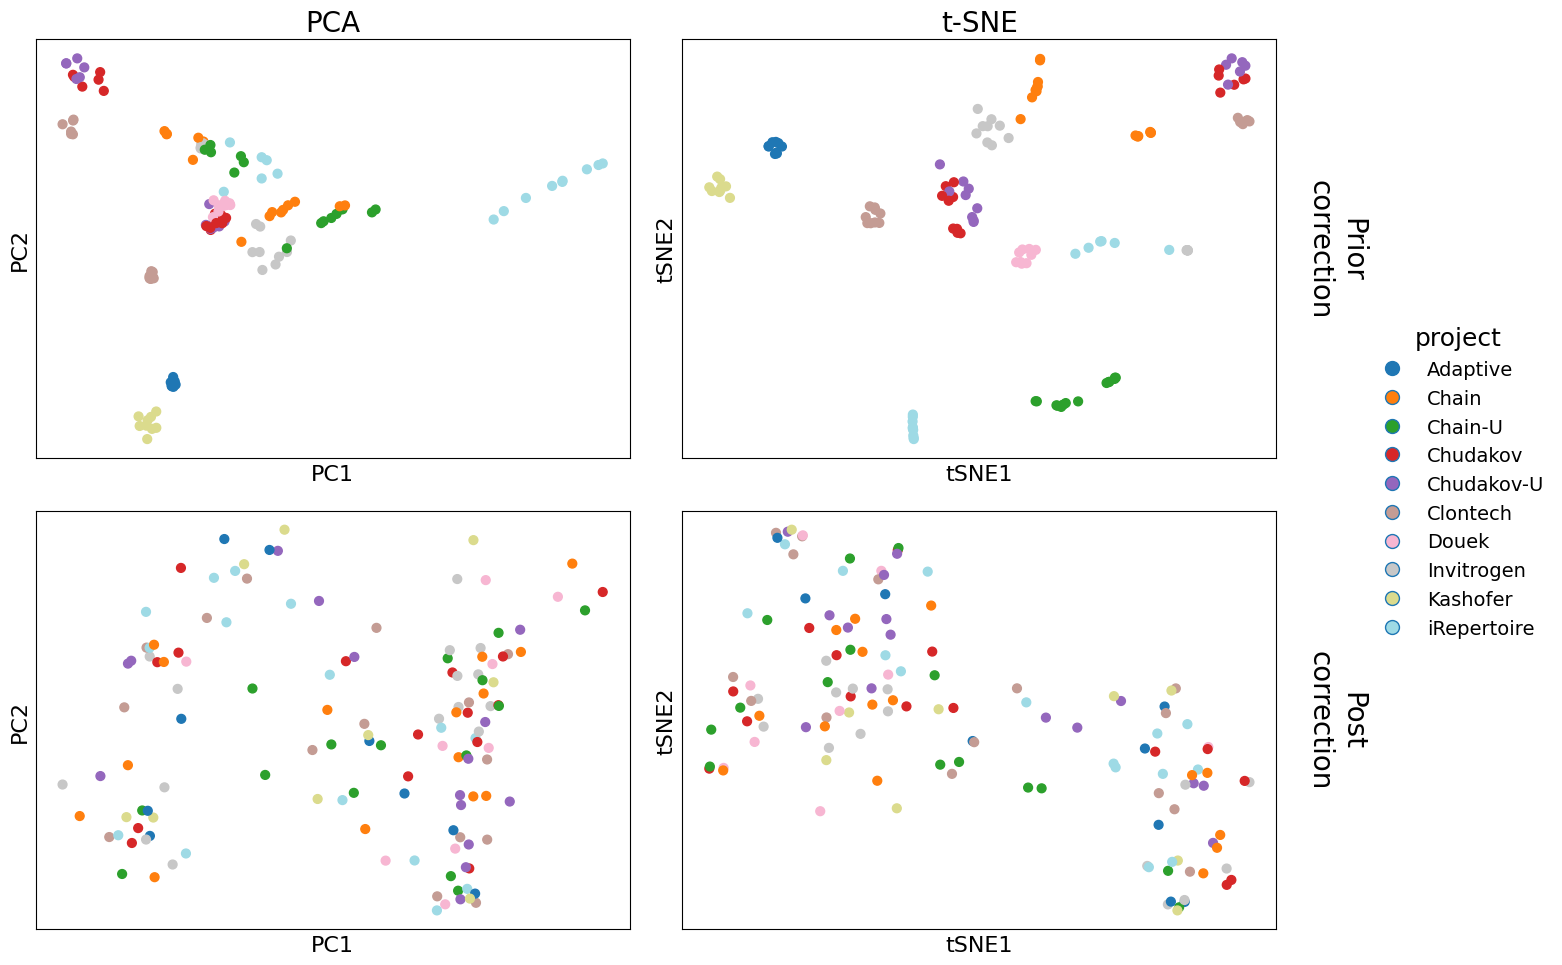

In [109]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import pandas as pd

plt.rcParams.update({
    "font.size": 18,
    "axes.titlesize": 20,
    "legend.fontsize": 14,
    "axes.spines.top": True,
    "axes.spines.right": True,
})

# Берём проекты
projects = dataset.metadata.project
proj_cat = pd.Categorical(projects)
colors = proj_cat.codes
labels = proj_cat.categories

# PCA / t-SNE
pca_norm = PCA(n_components=2).fit_transform(norm_usage_table_v.segment_usage_matrix)
tsne_norm = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(norm_usage_table_v.segment_usage_matrix)

pca_z = PCA(n_components=2).fit_transform(z_score_usage_table_v.segment_usage_matrix)
tsne_z = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(z_score_usage_table_v.segment_usage_matrix)

# === Рисуем фигуру ===
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

def scatter(ax, coords, xlab, ylab):
    ax.scatter(coords[:, 0], coords[:, 1], c=colors, cmap="tab20", s=40)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel(xlab)
    ax.set_ylabel(ylab)

# ==== Верхняя строка ====
scatter(axes[0, 0], pca_norm, "PC1", "PC2")
scatter(axes[0, 1], tsne_norm, "tSNE1", "tSNE2")
axes[0, 0].set_title("PCA")
axes[0, 1].set_title("t-SNE")

# ==== Нижняя строка ====
scatter(axes[1, 0], pca_z, "PC1", "PC2")
scatter(axes[1, 1], tsne_z, "tSNE1", "tSNE2")

# ==== Подписи строк (справа) ====
axes[0, 1].text(
    1.10, 0.5,
    "Prior\ncorrection",
    transform=axes[0, 1].transAxes,
    rotation=270, va="center", ha="center", fontsize=20
)

axes[1, 1].text(
    1.10, 0.5,
    "Post\ncorrection",
    transform=axes[1, 1].transAxes,
    rotation=270, va="center", ha="center", fontsize=20
)

# ==== Легенда (общая справа) ====
handles = [
    plt.Line2D([0], [0], marker='o', linestyle='',
               markerfacecolor=plt.cm.tab20(i / max(1, len(labels)-1)),
               markersize=10, label=lab)
    for i, lab in enumerate(labels)
]

fig.legend(handles=handles, title="project",
           bbox_to_anchor=(0.98, 0.5), loc="center left", frameon=False)

plt.tight_layout()
plt.show()
